# Retention analysis — Kalos Gym System (synthetic data)

**What this is:** the analysis I would run on the gym's real exports. It uses *synthetic* data generated by `synthetic_data.py`, under an explicitly assumed behaviour model, so the numbers below illustrate the method — they are **not** results from the real gym.

**Real measurement:** system launch was 26 Oct 2026; impact is measured over 3 months (closing 26 Jan 2027). The same notebook then runs on the real Sheet exports (students, renewals, attendance).

Questions: *(1)* How many members are still active after N months? *(2)* Does attendance frequency predict renewal? *(3)* When is the gym busy? *(4)* Can a simple "days since last visit" rule flag members at risk before they leave?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from synthetic_data import generate
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})
students, renewals, visits = generate()
print(len(students), 'students |', len(renewals), 'payments |', len(visits), 'visits')
renewals.head()

420 students | 1479 payments | 23978 visits


,id,date,plan,amount,kind
0,S0000,2026-03-07,Monthly,100,Signup
1,S0001,2026-04-29,Monthly,100,Signup
2,S0002,2026-02-04,Quarterly,270,Signup
3,S0002,2026-05-08,Quarterly,270,Renewal
4,S0002,2026-08-10,Quarterly,270,Renewal


## 1. Cohort retention
Share of each sign-up month's cohort that still holds a paid period N months later.

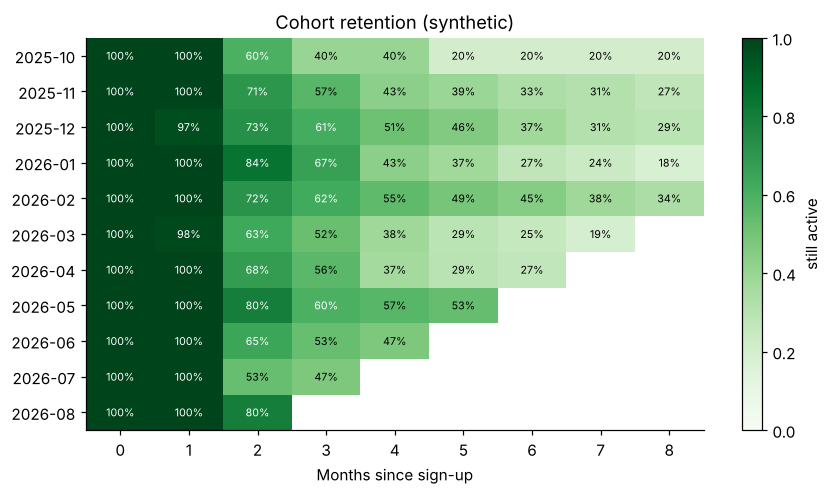

In [2]:
renewals['month'] = renewals['date'].dt.to_period('M')
first = renewals.groupby('id')['date'].min().dt.to_period('M').rename('cohort')
last = renewals.groupby('id')['date'].max()
last_end = (last + pd.to_timedelta(renewals.groupby('id')['plan'].last().map({'Monthly': 30, '3x/week': 30, 'Quarterly': 90}), unit='D'))
life = ((last_end.dt.to_period('M') - first).apply(lambda x: x.n)).rename('months_active')
df = pd.concat([first, life], axis=1).reset_index()
cohorts = sorted(df['cohort'].unique())[:-1]
grid = pd.DataFrame({c: [(df[(df.cohort == c)]['months_active'] >= m).mean() if (pd.Timestamp('2026-10-01').to_period('M') - c).n >= m else np.nan for m in range(0, 9)] for c in cohorts}, index=range(0, 9)).T
fig, ax = plt.subplots(figsize=(8, 4.6)); im = ax.imshow(grid.values, cmap='Greens', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(9)); ax.set_yticks(range(len(grid))); ax.set_yticklabels([str(c) for c in grid.index]); ax.set_xlabel('Months since sign-up'); ax.set_title('Cohort retention (synthetic)'); ax.grid(False)
for (r, c), v in np.ndenumerate(grid.values):
    if not np.isnan(v): ax.text(c, r, f'{v:.0%}', ha='center', va='center', fontsize=7, color='black' if v < .6 else 'white')
fig.colorbar(im, label='still active'); plt.tight_layout(); plt.show()

## 2. Does attendance predict renewal?
For every paid period: visits per week during it, and whether a next period followed within 10 days (the same grace window the owner panel uses).

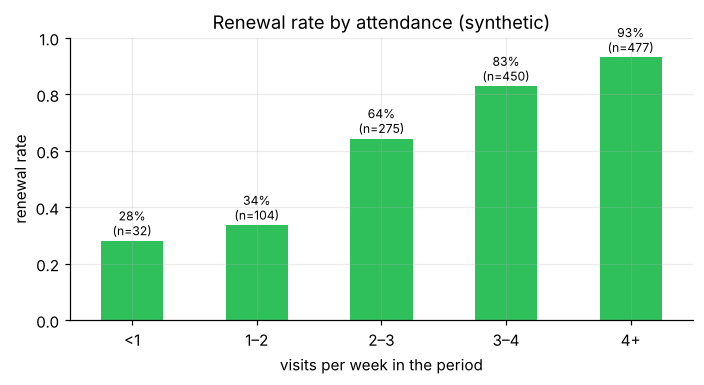

In [3]:
plan_days = {'Monthly': 30, '3x/week': 30, 'Quarterly': 90}
r = renewals.sort_values(['id', 'date']).copy()
r['end'] = r['date'] + pd.to_timedelta(r['plan'].map(plan_days) - 1, unit='D')
r['next_start'] = r.groupby('id')['date'].shift(-1)
r['renewed'] = (r['next_start'] - r['end']).dt.days.le(10)
r = r[r['end'] < pd.Timestamp('2026-10-17')]                      # only periods whose outcome is already known
v = visits.copy(); v['date'] = pd.to_datetime(v['date'])
def n_visits(row):
    m = (v['id'] == row['id']) & (v['date'] >= row['date']) & (v['date'] <= row['end']); return m.sum()
r['visits_pw'] = r.apply(n_visits, axis=1) / (r['plan'].map(plan_days) / 7)
r['bucket'] = pd.cut(r['visits_pw'], [-.01, 1, 2, 3, 4, 6], labels=['<1', '1–2', '2–3', '3–4', '4+'])
rate = r.groupby('bucket', observed=True)['renewed'].agg(['mean', 'count'])
ax = rate['mean'].plot.bar(figsize=(6.5, 3.6), color='#2fbf5b', rot=0); ax.set_ylim(0, 1); ax.set_ylabel('renewal rate'); ax.set_xlabel('visits per week in the period'); ax.set_title('Renewal rate by attendance (synthetic)')
for i, (m, c) in enumerate(zip(rate['mean'], rate['count'])): ax.text(i, m + .02, f'{m:.0%}\n(n={c})', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

## 3. When is the gym busy?

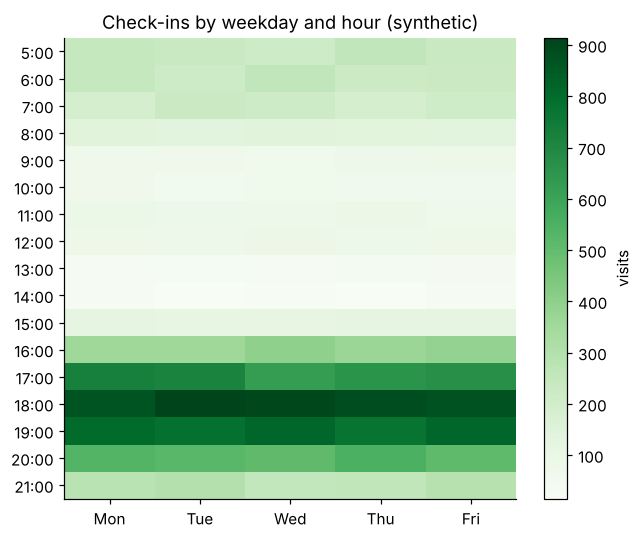

In [4]:
v['weekday'] = v['date'].dt.dayofweek
heat = v.pivot_table(index='hour', columns='weekday', values='id', aggfunc='count', fill_value=0)
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(heat.values, cmap='Greens', aspect='auto'); ax.grid(False)
ax.set_xticks(range(5)); ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri']); ax.set_yticks(range(len(heat))); ax.set_yticklabels([f'{h}:00' for h in heat.index])
ax.set_title('Check-ins by weekday and hour (synthetic)'); fig.colorbar(im, label='visits'); plt.tight_layout(); plt.show()

## 4. A simple early-warning rule
Flag a member as *at risk* when they have not visited for **N** days while their plan is still active. How well does each N separate members who renew from those who don't?

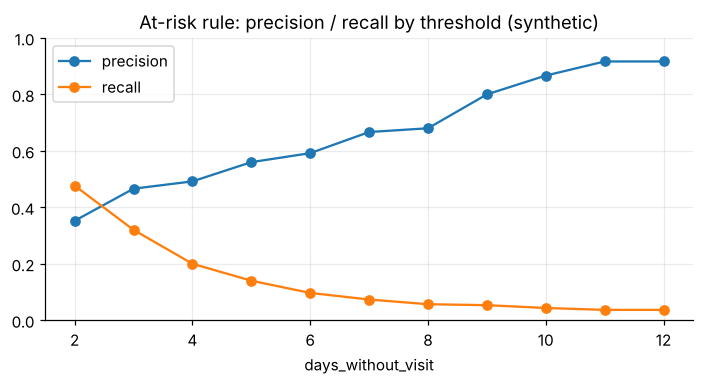

,flagged,precision,recall
days_without_visit,,,
2,406,0.35,0.48
3,206,0.47,0.32
4,122,0.49,0.20
5,75,0.56,0.14
6,49,0.59,0.10
7,33,0.67,0.07
8,25,0.68,0.06
9,20,0.80,0.05
10,15,0.87,0.04


In [5]:
rows = []
for _, p in r.iterrows():
    cut = p['end'] - pd.Timedelta(days=7)                           # evaluate one week before the plan ends
    vv = v[(v['id'] == p['id']) & (v['date'] >= p['date']) & (v['date'] <= cut)]['date']
    gap = (cut - vv.max()).days if len(vv) else (cut - p['date']).days
    rows.append(gap)
r['gap'] = rows
out = []
for n in range(2, 13):
    flag = r['gap'] >= n; churn = ~r['renewed']
    tp = (flag & churn).sum(); out.append(dict(days_without_visit=n, flagged=int(flag.sum()), precision=tp / max(flag.sum(), 1), recall=tp / max(churn.sum(), 1)))
res = pd.DataFrame(out).set_index('days_without_visit')
ax = res[['precision', 'recall']].plot(figsize=(6.5, 3.6), marker='o'); ax.set_ylim(0, 1); ax.set_title('At-risk rule: precision / recall by threshold (synthetic)'); plt.tight_layout(); plt.show()
res.round(2)

## Takeaways (on synthetic data)
* Method: cohort retention, attendance-to-renewal link, load heatmap and a threshold rule evaluated with precision/recall.
* The owner panel already surfaces a live version of (4): *who did not come back* and *who is about to expire*.
* Next, with real data: replace the three DataFrames, add the notification-enabled flag as a feature, and compare renewal rate before and after launch (26 Oct 2026).